# **Diabetes Disease Progression Prediction**

## **Introduction**:
This project focuses on developing machine learning regression models to predict diabetes disease progression using the Diabetes dataset available in Scikit-learn.

## **1. Review of Machine Learning Concepts**

#### **1.1 Definition and types of machine learning**

Machine Learning is a branch of Artificial Intelligence (AI) that enables computers to learn patterns from data and use those patterns to make predictions or decisions. 

We have 3 main types of machine learning:

**Supervised Learning**: Uses labeled data to train models for predicting outcomes, such as classification and regression.

**Unsupervised Learning**: Uses unlabeled data to identify patterns and group similar observations through clustering.

**Reinforcement Learning**: Learns through interactions with an environment using rewards and penalties.

Supervised learning uses a training dataset to learn relationships between input features and known target values. The trained model then makes predictions on unseen test data. Its performance is evaluated using metrics such as R² and RMSE for regression, or Accuracy, Precision, Recall, and F1-score for classification.

#### **1.2 Key components of ML:**

**Features**: These are input variables also known as independent variables or attributes that the model uses to make predictions. Example: age, BMI, and blood pressure.

**Labels**: These are targets or dependent variables or outcome that the model predict. Eg: diabetes disease progression.

**Model training**: Involves using the algorithm to learn the patterns or relationship between features and labels using the training data.

**Model Evaluation**: Measuring prediction performance using metrics such as R² and RMSE for regression

**Prediction**: Using the trained model to estimate outcomes for new, unseen data.



## **2. Data Preparation and Exploration**

### **2.1 Load the Diabetes dataset**

In [31]:
# Import libraries

from sklearn.datasets import load_diabetes
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from sklearn.model_selection import GridSearchCV


In [4]:
# Loard the dataset
diabetes = load_diabetes()

# Create DataFrame
df_diabetes = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df_diabetes["target"] = diabetes.target

# Display first five rows
display(df_diabetes.head())

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


### **2.2 EDA**

In [8]:
df_diabetes.shape

(442, 11)

In [6]:
df_diabetes.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [9]:
df_diabetes.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


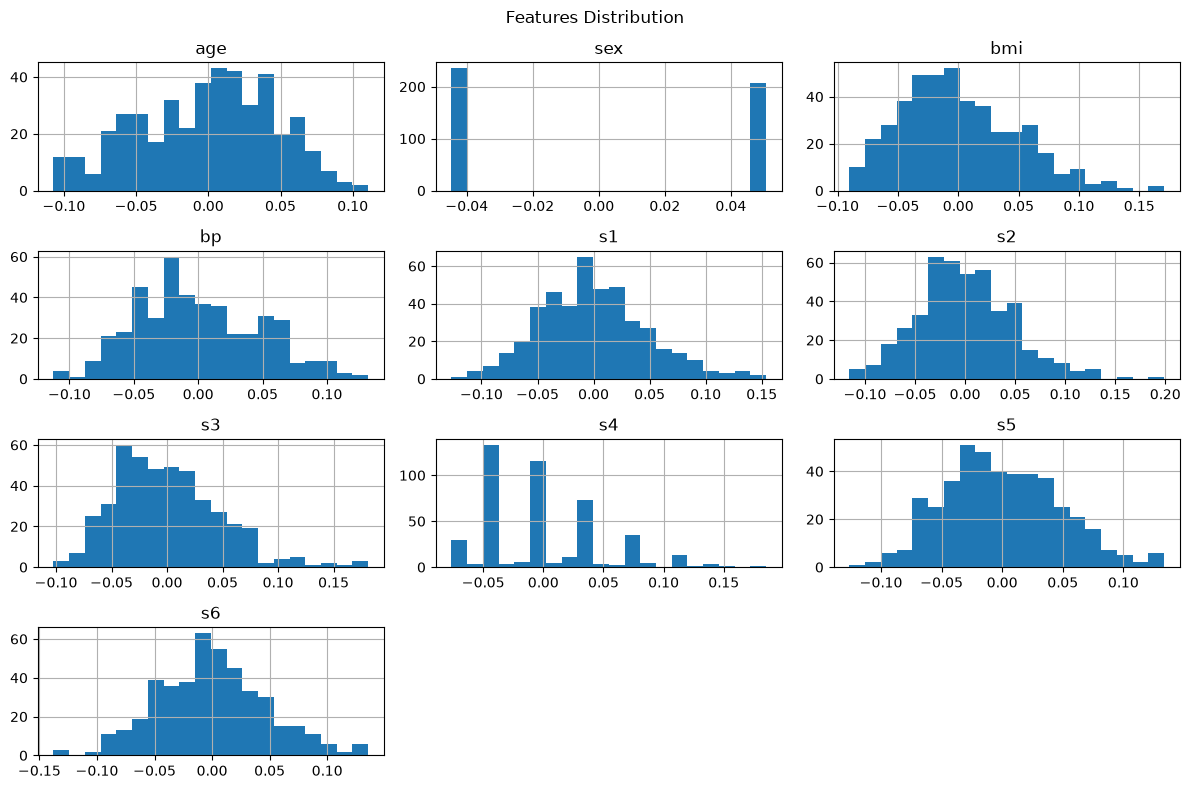

In [11]:
# Visualize the features distribution

df_diabetes.drop(columns="target").hist(figsize=(12, 8), bins=20)

plt.suptitle("Features Distribution")
plt.tight_layout()
plt.show()

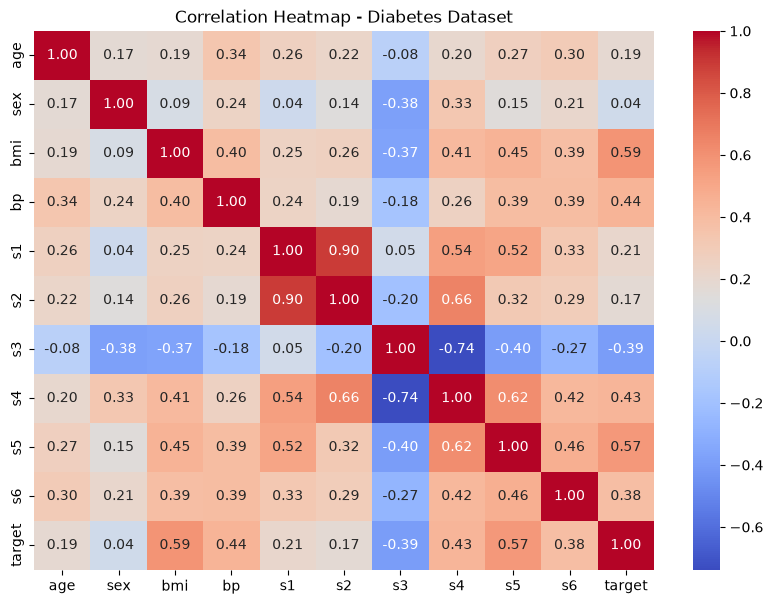

In [13]:
# Visualize the correlation 

correlation = df_diabetes.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap - Diabetes Dataset")
plt.show()

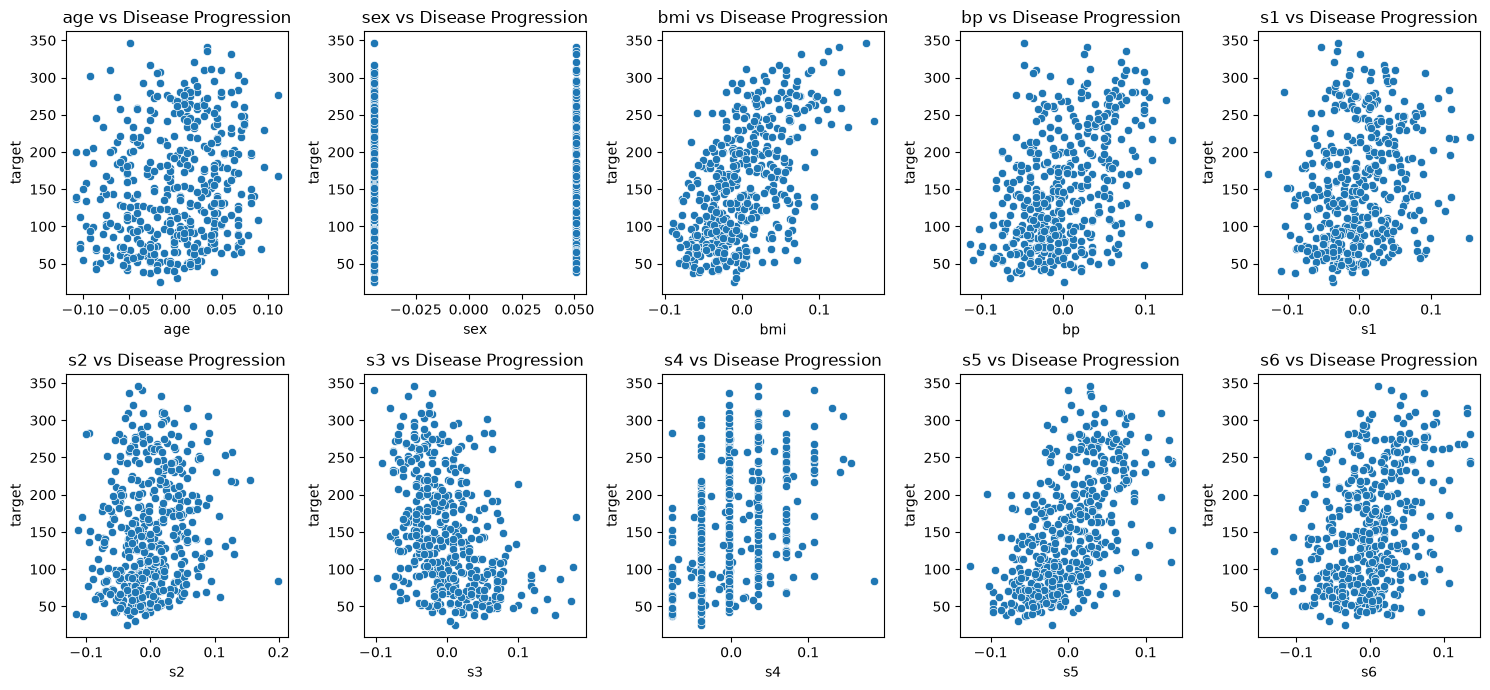

In [ ]:
# Scatter plots for all features against the target

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for ax, feature in zip(axes.flat, diabetes.feature_names):
    sns.scatterplot(data=df_diabetes, x=feature, y="target", ax=ax)
    ax.set_title(f"{feature} vs Disease Progression")

plt.tight_layout()
plt.show()

## **3. Data Cleaning and Feature Engineering**

### **3.1 Identify anomalies**

In [19]:
# Check missing values
print(df_diabetes.isnull().sum())

age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64


In [20]:
# Check duplicates
print("Duplicates:", df_diabetes.duplicated().sum())

Duplicates: 0


In [22]:
# Check data types
print(df_diabetes.dtypes)

age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object


### **3.2 Split the dataset**

In [17]:
# Split the dataset

X_diabetes = df_diabetes.drop(columns="target")
y_diabetes = df_diabetes["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X_diabetes, y_diabetes,
    test_size=0.2,
    random_state=42)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (353, 10)
Testing: (89, 10)


### **3.3 Standardize data**

No scaling was performed as the data are already standardized

In [23]:
# Correlation with target

correlation = df_diabetes.corr()["target"].drop("target")

print(correlation.sort_values(ascending=False))

bmi    0.586450
s5     0.565883
bp     0.441482
s4     0.430453
s6     0.382483
s1     0.212022
age    0.187889
s2     0.174054
sex    0.043062
s3    -0.394789
Name: target, dtype: float64


## **4. Model Selection and Training**

In [25]:
# Initialize the models

models_diabetes = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)}

In [26]:
# Train the models and make predictions

predictions_diabetes = {}

for name, model in models_diabetes.items():

    # Train model
    model.fit(X_train, y_train)

    # Make predictions
    predictions_diabetes[name] = model.predict(X_test)

    print(name, "trained successfully")

Linear Regression trained successfully
Ridge Regression trained successfully
Lasso Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully


#### **Model complexity and interpretability**:

Linear Regression: Simple and easy to interpret, but may miss nonlinear relationships.

Ridge Regression: Reduces overfitting by shrinking coefficients.

Lasso Regression: Can reduce some coefficients to zero, helping with feature selection.

Decision Tree: Captures nonlinear relationships but may overfit.

Random Forest: Combines multiple trees to improve predictive stability, but is harder to interpret.

Five regression models were selected to predict diabetes disease progression. Linear Regression served as the baseline, while Ridge and Lasso introduced regularization to control model complexity. Decision Tree and Random Forest were included to explore nonlinear relationships.

## **5. Model Evaluation**

In [29]:
# Model evaluation

results_diabetes = []

for name, y_pred in predictions_diabetes.items():
    results_diabetes.append({
        "Model": name,
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R²": r2_score(y_test, y_pred)})

evaluation_diabetes = pd.DataFrame(results_diabetes)

display(evaluation_diabetes.round(4))

,Model,MSE,RMSE,MAE,R²
0,Linear Regression,2900.1936,53.8534,42.7941,0.4526
1,Ridge Regression,3077.4159,55.4745,46.1389,0.4192
2,Lasso Regression,2878.5594,53.6522,42.8318,0.4567
3,Decision Tree,4976.7978,70.5464,54.5281,0.0607
4,Random Forest,2952.0106,54.3324,44.0530,0.4428


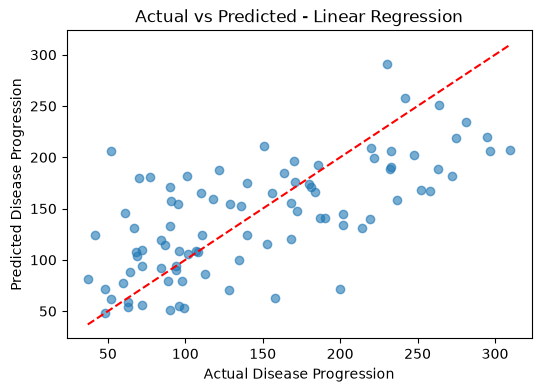

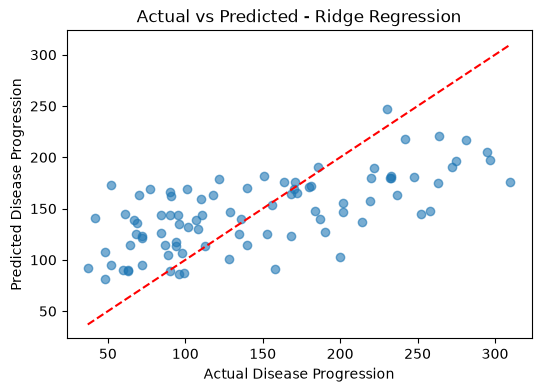

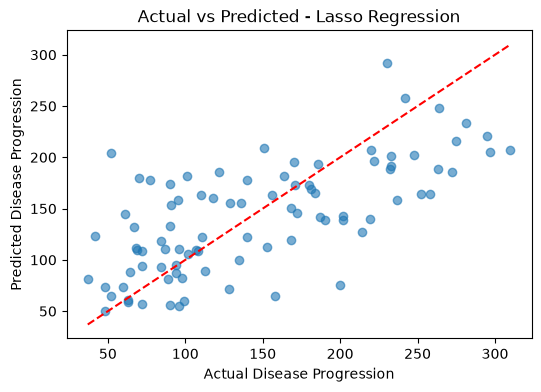

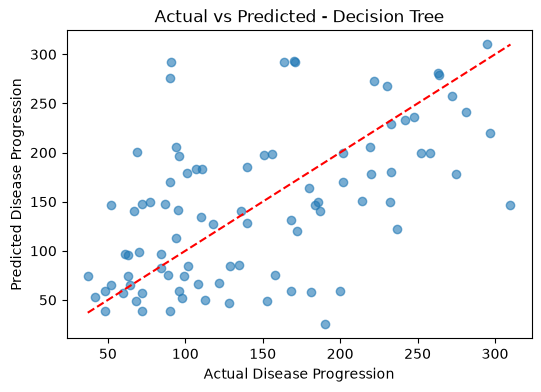

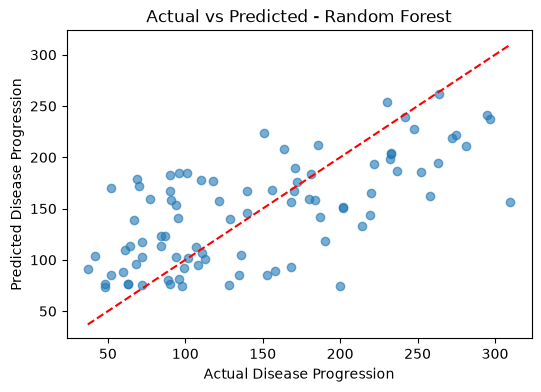

In [ ]:
# Visualize actual vs. predicted values

for name, y_pred in predictions_diabetes.items():

    plt.figure(figsize=(6, 4))

    plt.scatter(y_test, y_pred, alpha=0.6)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')

    plt.xlabel("Actual Disease Progression")
    plt.ylabel("Predicted Disease Progression")
    plt.title(f"Actual vs Predicted - {name}")
    plt.show()

## **6. Hyperparameter Tuning and Optimization**

#### **6.1 Define models and hyperparameters**

In [32]:
param_grids = {
    "Ridge Regression": {
        "alpha": [0.01, 0.1, 1, 10]
    },
    "Lasso Regression": {
        "alpha": [0.001, 0.01, 0.1, 1]
    },
    "Decision Tree": {
        "max_depth": [2, 3, 5, 10],
        "min_samples_leaf": [2, 5, 10]
    },
    "Random Forest": {
        "n_estimators": [50, 100, 200],
        "max_depth": [3, 5, 10],
        "min_samples_leaf": [2, 5]
    }
}

#### **6.2 Perform Grid Search**

In [ ]:
best_models = {}

for name, params in param_grids.items():

    grid = GridSearchCV(
        models_diabetes[name],
        params,
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    print(name)
    print("Best Parameters:", grid.best_params_)
    print("Cross-validation RMSE:", round(-grid.best_score_, 4))
    print()

Ridge Regression
Best Parameters: {'alpha': 0.1}
Cross-validation RMSE: 55.842

Lasso Regression
Best Parameters: {'alpha': 0.1}
Cross-validation RMSE: 55.8873

Decision Tree
Best Parameters: {'max_depth': 2, 'min_samples_leaf': 2}
Cross-validation RMSE: 61.2638

Random Forest
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 200}
Cross-validation RMSE: 58.093



#### **6.3 Evaluate optimized models**

In [34]:
optimized_results = []

# Include original Linear Regression as baseline
best_models["Linear Regression"] = models_diabetes["Linear Regression"]

for name, model in best_models.items():

    y_pred = model.predict(X_test)

    optimized_results.append({
        "Model": name,
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R²": r2_score(y_test, y_pred)
    })

optimized_df = pd.DataFrame(optimized_results)

display(optimized_df.sort_values("RMSE").round(4))

,Model,MSE,RMSE,MAE,R²
1,Lasso Regression,2798.1935,52.8980,42.8544,0.4719
0,Ridge Regression,2856.4869,53.4461,42.9969,0.4609
3,Random Forest,2857.1872,53.4527,43.4544,0.4607
4,Linear Regression,2900.1936,53.8534,42.7941,0.4526
2,Decision Tree,3735.4996,61.1187,49.3653,0.2949


#### **6.4 Compare original and optimized models**

In [35]:
comparison = evaluation_diabetes.merge(
    optimized_df,
    on="Model",
    suffixes=("_Before", "_After")
)

display(comparison[[
    "Model",
    "RMSE_Before",
    "RMSE_After",
    "R²_Before",
    "R²_After"
]].round(4))

,Model,RMSE_Before,RMSE_After,R²_Before,R²_After
0,Linear Regression,53.8534,53.8534,0.4526,0.4526
1,Ridge Regression,55.4745,53.4461,0.4192,0.4609
2,Lasso Regression,53.6522,52.8980,0.4567,0.4719
3,Decision Tree,70.5464,61.1187,0.0607,0.2949
4,Random Forest,54.3324,53.4527,0.4428,0.4607


#### **6.5 Select the best model**

In [36]:
best_model_name = optimized_df.loc[
    optimized_df["RMSE"].idxmin(), "Model"
]

print("Best Model:", best_model_name)

Best Model: Lasso Regression
